# Solace Health Clinics – Evidenz-Review

**Modulprojekt Statistics & A/B Testing** · Datensatz: `solace_visits.csv` (ein Besuch pro Zeile, vier Kliniken)

Dieses Notebook bündelt die vier Projekt-Checkpoints zu einem Dokument:

| Teil | Frage |
|---|---|
| **1** | Kannst du diesen Daten vertrauen? (Daten-Audit, Zusammenfassung, Zusammenhänge) |
| **2** | Einseitiger Test: Warten Patienten in Downtown im Schnitt weniger als 15 Minuten? |
| **3** | Zweiseitiger Vergleich: Warten Patienten in Riverside anders als in Downtown? |
| **4** | Design-Review: Sollte der SMS-Erinnerungstest so durchgeführt werden? |
| **5** | Diagramme mit je einem Satz, den sie belegen |

**Ausführen:** Kernel neu starten und alle Zellen von oben nach unten laufen lassen. Die CSV wird unter dem Dateinamen `solace_visits.csv` gesucht (neben dem Notebook oder im Kurs-Drive-Ordner). Jede im Bericht zitierte Zahl wird in einer Zelle dieses Notebooks erzeugt.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, skew

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
ABB = Path("abbildungen")
ABB.mkdir(exist_ok=True)


def finde_csv(name="solace_visits.csv"):
    """Sucht die CSV unter dem vorgegebenen Dateinamen neben dem Notebook oder im Kurs-Drive-Ordner."""
    for ordner in [Path.cwd(), Path.cwd().parent]:
        for pfad in [ordner / name, *ordner.glob(f"*/*/*/{name}")]:
            if pfad.exists():
                return pfad
    raise FileNotFoundError(f"{name} nicht gefunden - bitte neben das Notebook legen.")


csv_path = finde_csv()
df = pd.read_csv(csv_path)
print("Datei:", csv_path.name, "|", df.shape[0], "Zeilen,", df.shape[1], "Spalten")
df.head(3)

Datei: solace_visits.csv | 1209 Zeilen, 14 Spalten


,visit_id,patient_id,appointment_date,clinic_site,appointment_type,insurance_type,day_of_week,no_show,wait_time_min,patient_satisfaction,scheduled_duration_min,actual_duration_min,visit_cost,zip_code
0,R-00001,P-0001,2026-02-28,Downtown,Specialist,Private,Saturday,0,15.72,3.0,30,23.54,228.12,8540
1,R-00002,P-0002,2026-02-12,Northgate,Checkup,Private,Thursday,0,8.57,4.0,15,9.83,118.09,7030
2,R-00003,P-0139,2026-01-08,Downtown,Follow-up,Self-pay,Thursday,1,4.88,NaN,45,23.93,257.17,6510


---
# Teil 1 – Checkpoint 1: Kannst du diesen Daten vertrauen?

**Reihenfolge:** Zuerst wird der Datensatz geprüft (fehlende Werte, Duplikate, Spaltentypen), dann die Ausreißerregel festgelegt, und erst danach wird zusammengefasst. Was geändert wurde, steht in einem Änderungsprotokoll.

## 1.1 Überblick

In [2]:
print(df.dtypes)
print()
print("Fehlende Werte pro Spalte (nur Spalten mit Lücken):")
print(df.isna().sum()[df.isna().sum() > 0])

visit_id                      str
patient_id                    str
appointment_date              str
clinic_site                   str
appointment_type              str
insurance_type                str
day_of_week                   str
no_show                     int64
wait_time_min             float64
patient_satisfaction      float64
scheduled_duration_min      int64
actual_duration_min       float64
visit_cost                float64
zip_code                    int64
dtype: object

Fehlende Werte pro Spalte (nur Spalten mit Lücken):
patient_satisfaction    123
dtype: int64


Auffällig: Nur `patient_satisfaction` hat Lücken (123). Und `zip_code` ist als Zahl gespeichert, obwohl eine Postleitzahl eine Kennung ist.

## 1.2 Fehlende Werte: Wie viele und warum?

In [3]:
miss = df.groupby("appointment_type")["patient_satisfaction"].apply(lambda s: s.isna().mean() * 100).round(1)
print(f"Gesamt fehlend: {df['patient_satisfaction'].isna().mean() * 100:.1f} %")
print("\nnach Terminart:\n", miss.sort_values(ascending=False).to_string())
print("\nBesuche pro Terminart:\n", df["appointment_type"].value_counts().to_string())
print("\nnach Klinik:\n", df.groupby("clinic_site")["patient_satisfaction"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_string())

Gesamt fehlend: 10.2 %

nach Terminart:
 appointment_type
Urgent        31.5
Checkup        5.3
Follow-up      4.8
Specialist     4.7

Besuche pro Terminart:
 appointment_type
Checkup       494
Follow-up     351
Urgent        235
Specialist    129

nach Klinik:
 clinic_site
Downtown     10.0
Eastview     10.4
Northgate     9.4
Riverside    11.0


**Befund:** Insgesamt fehlen 10,2 %, aber bei **Urgent 31,5 %** gegenüber rund 5 % bei den anderen Terminarten. Das liegt nicht an der Gruppengröße (die kleinste Gruppe, Specialist, hat die niedrigste Rate) und nicht an der Klinik (9,4 bis 11,0 %). Das Fehlen folgt der Terminart und ist **nicht zufällig**.

**Entscheidung:** Zeilen mit Lücken werden **nicht gelöscht und nicht aufgefüllt**. Die Lücke wird markiert, und die Rücklaufquote wird neben jedem Zufriedenheits-Durchschnitt berichtet. *Verworfen:* Löschen (würde Urgent unterrepräsentieren) und Auffüllen mit dem Mittelwert (stellt keinen wahren Wert wieder her, wiederholt nur die Verzerrung).

                  zufriedenheit  ruecklauf_pct
appointment_type                              
Checkup                    4.11           94.7
Follow-up                  4.11           95.2
Specialist                 4.11           95.3
Urgent                     4.06           68.5


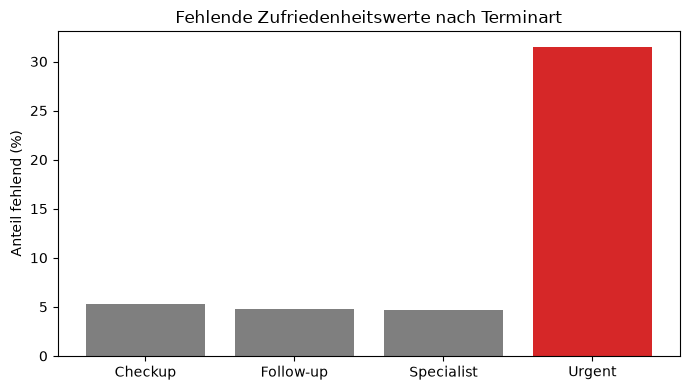

In [4]:
df["satisfaction_missing"] = df["patient_satisfaction"].isna()
bericht = df.groupby("appointment_type").agg(
    zufriedenheit=("patient_satisfaction", "mean"),
    ruecklauf_pct=("satisfaction_missing", lambda s: round((1 - s.mean()) * 100, 1)),
).round(2)
print(bericht)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(miss.index, miss.values, color=["tab:red" if t == "Urgent" else "tab:gray" for t in miss.index])
ax.set(title="Fehlende Zufriedenheitswerte nach Terminart", ylabel="Anteil fehlend (%)")
plt.tight_layout(); plt.savefig(ABB / "abb4_fehlwerte.png", dpi=150); plt.show()

*Aussage dieses Diagramms:* Die Lücken konzentrieren sich in Urgent. Ein Zufriedenheits-Durchschnitt für Urgent stützt sich auf nur 68,5 % der Besuche.

## 1.3 Doppelte Datensätze

In [5]:
daten = df.drop(columns="satisfaction_missing")
exakt = daten.duplicated(keep=False)
locker = daten.duplicated(subset=["patient_id", "appointment_date"], keep=False)
print("Exakte Duplikatzeilen (jede Spalte gleich):", exakt.sum(), "=", exakt.sum() // 2, "Paare")
print("Gleicher Patient + gleiches Datum:", locker.sum(), "Zeilen")
print("Davon keine echten Duplikate:", (locker & ~exakt).sum())
daten[locker & ~exakt].sort_values("patient_id")[["visit_id", "patient_id", "appointment_date", "appointment_type", "clinic_site"]].head(6)

Exakte Duplikatzeilen (jede Spalte gleich): 18 = 9 Paare
Gleicher Patient + gleiches Datum: 58 Zeilen
Davon keine echten Duplikate: 40


,visit_id,patient_id,appointment_date,appointment_type,clinic_site
2,R-00003,P-0139,2026-01-08,Follow-up,Downtown
138,R-00139,P-0139,2026-01-08,Checkup,Downtown
174,R-00174,P-0174,2026-02-28,Checkup,Northgate
430,R-00430,P-0174,2026-02-28,Follow-up,Downtown
181,R-00181,P-0181,2026-01-08,Checkup,Downtown
959,R-00952,P-0181,2026-01-08,Follow-up,Downtown


**Befund:** Nur **18 Zeilen (9 Paare)** stimmen in *jeder* Spalte überein (gleiche `visit_id`). Die lockere Regel „gleicher Patient am gleichen Tag“ würde 58 Zeilen markieren, davon wären **40 echte Zweitbesuche** (andere Terminart, oft andere Klinik).

**Entscheidung:** Nur die 9 exakten Duplikate werden entfernt (eine Kopie bleibt). *Verworfen:* die lockere Regel, weil sie 40 echte Besuche zerstört hätte.

## 1.4 Spaltentypen und Kategorien

In [6]:
print("zip_code Typ:", df["zip_code"].dtype, "| Werte unter 5 Stellen:", int((df["zip_code"] < 10000).sum()), "von", len(df))
print("Kategorien auf Leerzeichen/Schreibweise geprüft:")
for col in ["clinic_site", "appointment_type", "insurance_type", "day_of_week"]:
    sauber = (df[col].str.strip() == df[col]).all() and df[col].nunique() == df[col].str.lower().nunique()
    print(f"  {col}: {df[col].nunique()} Werte, sauber = {sauber}")

zip_code Typ: int64 | Werte unter 5 Stellen: 1209 von 1209
Kategorien auf Leerzeichen/Schreibweise geprüft:
  clinic_site: 4 Werte, sauber = True
  appointment_type: 4 Werte, sauber = True
  insurance_type: 4 Werte, sauber = True
  day_of_week: 7 Werte, sauber = True


**Befund:** `zip_code` ist als Zahl gespeichert und hat in **allen** Zeilen die führende Null verloren (`08540` wurde `8540`). Die Kategorien sind sauber.

**Entscheidung:** `zip_code` wird als Text mit führender Null (5 Stellen) geführt. Das ist sicher, weil keine Postleitzahl länger als 5 Stellen ist. *Verworfen:* so lassen (Verknüpfungen mit Referenztabellen würden still fehlschlagen). Für die Kategorien: **keine Änderung nötig**, bewusst geprüft statt angenommen.

## 1.5 Bereinigten Datensatz erzeugen

In [7]:
clean = df.drop(columns="satisfaction_missing").drop_duplicates(keep="first").copy()
clean["zip_code"] = clean["zip_code"].astype(str).str.zfill(5)
clean["satisfaction_missing"] = clean["patient_satisfaction"].isna()
print(f"Zeilen vorher: {len(df)}, nachher: {len(clean)} (entfernt: {len(df) - len(clean)})")
print("zip_code:", sorted(clean["zip_code"].unique()))
print("Max. Länge zip_code:", clean["zip_code"].str.len().max())

Zeilen vorher: 1209, nachher: 1200 (entfernt: 9)
zip_code: ['02134', '02139', '02445', '06510', '07001', '07030', '08540']
Max. Länge zip_code: 5


## 1.6 Änderungsprotokoll

| Problem | Befund | Entscheidung | Verworfene Alternative |
|---|---|---|---|
| Fehlende Zufriedenheit | 123 (10,2 %), Urgent 31,5 % vs. ~5 % | markieren, Rücklaufquote berichten | löschen / mit Mittelwert auffüllen |
| Doppelte Datensätze | 18 exakte Zeilen (9 Paare); lockere Regel würde 58 markieren | 9 Kopien entfernt (1.209 → 1.200) | alle 58 entfernen (zerstört 40 echte Besuche) |
| Spaltentyp `zip_code` | als Zahl gespeichert, führende Null fehlt überall | als Text, 5 Stellen | unverändert lassen |
| Kategorienspalten | sauber | **keine Änderung** | – |
| Ausreißer | siehe 1.8 | **markiert, nicht gelöscht** | löschen |

## 1.7 Welches Problem hätte eine Schlussfolgerung verändert?

In [8]:
def kennzahlen(x):
    d = x[x.clinic_site == "Downtown"]["wait_time_min"]
    r = x[x.clinic_site == "Riverside"]["wait_time_min"]
    return {
        "Zeilen": len(x),
        "Mittelwert visit_cost": round(x["visit_cost"].mean(), 2),
        "Median visit_cost": round(x["visit_cost"].median(), 2),
        "Downtown Mittelwert Wartezeit": round(d.mean(), 2),
        "Riverside minus Downtown (Min.)": round(r.mean() - d.mean(), 2),
        "Urgent Zufriedenheit (Mittel)": round(x[x.appointment_type == "Urgent"]["patient_satisfaction"].mean(), 3),
        "Urgent Rücklaufquote (%)": round(x[x.appointment_type == "Urgent"]["patient_satisfaction"].notna().mean() * 100, 1),
    }


vergleich = pd.DataFrame({"Rohdaten": kennzahlen(df), "bereinigt": kennzahlen(clean)})
vergleich

,Rohdaten,bereinigt
Zeilen,1209.000,1200.000
Mittelwert visit_cost,190.730,190.830
Median visit_cost,157.040,157.280
Downtown Mittelwert Wartezeit,12.180,12.180
Riverside minus Downtown (Min.),8.540,8.580
Urgent Zufriedenheit (Mittel),4.062,4.063
Urgent Rücklaufquote (%),68.500,68.200


- **Doppelte Datensätze:** ändern die Kennzahlen kaum (z. B. Mittelwert Besuchskosten 190,73 → 190,83; Differenz Riverside–Downtown 8,54 → 8,58 Minuten). Keine der Schlussfolgerungen dieses Projekts würde kippen. Sie zu übersehen hätte aber Zählungen um 9 Besuche aufgebläht.
- **Fehlende Werte:** verändern die **Aussage über Zufriedenheit**. Der Urgent-Durchschnitt (4,06) stützt sich nur auf 68,5 % der Urgent-Besuche. Ohne Hinweis auf die Rücklaufquote würde er als vollständig gelesen.
- **`zip_code`-Typ:** ändert keine der hier berechneten Zahlen, weil die Spalte nirgends verwendet wird. Das Problem würde erst bei Verknüpfungen oder Auswertungen nach Region sichtbar.

**Ab hier arbeitet das Notebook mit `clean`.** Die Checkpoints 2 und 3 reproduzieren zuerst die im Kurs gezeigte Ausgabe (Rohdaten) und prüfen dann, dass `clean` dieselbe Schlussfolgerung liefert.

## 1.8 Ausreißerregel (vor der Anwendung festgelegt)

> **Regel:** Ein Wert gilt als markiert, wenn er größer ist als **Q3 + 1,5 × IQR** (IQR = Q3 − Q1) oder kleiner als **Q1 − 1,5 × IQR**.
> Markierte Werte werden **nicht gelöscht**, sondern angesehen und eingeordnet.

Die Regel steht hier, bevor eine Fallzahl berechnet wird.

In [9]:
def iqr_grenzen(s, faktor=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - faktor * (q3 - q1), q3 + faktor * (q3 - q1)


ausreisser = {}
for col in ["actual_duration_min", "visit_cost", "wait_time_min"]:
    unten, oben = iqr_grenzen(clean[col])
    maske = (clean[col] < unten) | (clean[col] > oben)
    ausreisser[col] = maske
    print(f"{col:22s} Grenzen {unten:8.1f} bis {oben:7.1f} -> markiert: {maske.sum():3d} ({maske.mean() * 100:.1f} %)")

actual_duration_min    Grenzen     -6.0 bis    51.3 -> markiert:  17 (1.4 %)
visit_cost             Grenzen    -70.3 bis   464.1 -> markiert:  15 (1.2 %)
wait_time_min          Grenzen     -9.5 bis    35.8 -> markiert:  32 (2.7 %)


In [10]:
# Dauer: gegen die geplante Dauer prüfen (Verhältnis)
dauer = clean[ausreisser["actual_duration_min"]].copy()
dauer["verhaeltnis"] = (dauer["actual_duration_min"] / dauer["scheduled_duration_min"]).round(1)
print(dauer.sort_values("verhaeltnis", ascending=False)[["visit_id", "scheduled_duration_min", "actual_duration_min", "verhaeltnis"]].to_string(index=False))
print("\n>= 3-fache Planung:", (dauer["verhaeltnis"] >= 3).sum(), "| milder:", (dauer["verhaeltnis"] < 3).sum())

# Kosten und Wartezeit: wie weit reichen die markierten Werte?
kosten = clean[ausreisser["visit_cost"]]
print("\nKosten markiert:", len(kosten), "| Bereich", kosten["visit_cost"].min().round(1), "bis", kosten["visit_cost"].max().round(1),
      "| verteilt auf Terminarten:", kosten["appointment_type"].value_counts().to_dict())
print("Wartezeit: Median", clean["wait_time_min"].median().round(1), "| Maximum", clean["wait_time_min"].max().round(1),
      "| markiert", ausreisser["wait_time_min"].sum())

visit_id  scheduled_duration_min  actual_duration_min  verhaeltnis
 R-00666                      30                399.0         13.3
 R-00313                      30                324.0         10.8
 R-00960                      30                306.0         10.2
 R-00965                      60                600.0         10.0
 R-01105                      45                418.5          9.3
 R-00202                      45                391.5          8.7
 R-00797                      60                456.0          7.6
 R-01144                      45                333.0          7.4
 R-00426                      30                204.0          6.8
 R-00633                      60                396.0          6.6
 R-00149                      60                384.0          6.4
 R-00828                      60                372.0          6.2
 R-01036                      60                366.0          6.1
 R-01015                      13                 74.1         

**Einordnung je Variable:**

| Variable | Markiert | Wirkt wie … | Begründung |
|---|---|---|---|
| `actual_duration_min` | 17 | **14 wie Fehler**, 3 harmlos | 14 Besuche dauerten das 5,7- bis 13,3-Fache der geplanten Zeit (z. B. 30 Min. geplant, 399 gedauert). Das ist kaum plausibel (vergessene Stoppuhr o. Ä.). Die 3 übrigen liegen bei ~1,3× und sind plausibel. Zwischen 1,3× und 5,7× liegt eine klare Lücke. |
| `visit_cost` | 15 | **echte Extremwerte** | Die Kosten sind rechtsschief. Die markierten Werte (ca. 464 bis 1.209 Dollar) verteilen sich auf mehrere Terminarten und bilden den langen Schwanz. |
| `wait_time_min` | 32 | **gewöhnlicher oberer Rand** | Wartezeiten sind von Natur aus rechtsschief (viele kurze, wenige lange). Das Maximum liegt bei rund 70 Minuten, plausibel. |

**Entscheidung:** Nichts wird gelöscht. Die 14 verdächtigen Dauern werden zur Prüfung markiert.

In [11]:
clean["duration_review_status"] = "not_flagged"
verh = clean["actual_duration_min"] / clean["scheduled_duration_min"]
clean.loc[ausreisser["actual_duration_min"] & (verh >= 3), "duration_review_status"] = "investigate_high_ratio"
print(clean["duration_review_status"].value_counts().to_string())

duration_review_status
not_flagged               1186
investigate_high_ratio      14


## 1.9 Fünf-Punkte-Zusammenfassung von `visit_cost` und Form der Verteilung

Minimum         70.86
Q1             130.13
Median         157.28
Q3             263.73
Maximum       1208.54
Mittelwert     190.83

Median - Q1 = 27.2 | Q3 - Median = 106.5 | Skewness = 2.49
Besuche über 500 Dollar: 9 von 1200


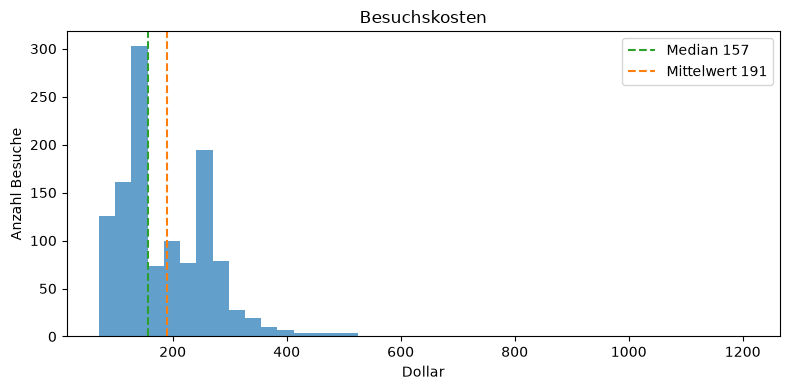

In [12]:
kosten_s = clean["visit_cost"]
fuenf = pd.Series({"Minimum": kosten_s.min(), "Q1": kosten_s.quantile(.25), "Median": kosten_s.median(),
                   "Q3": kosten_s.quantile(.75), "Maximum": kosten_s.max(), "Mittelwert": kosten_s.mean()}).round(2)
print(fuenf.to_string())
print(f"\nMedian - Q1 = {fuenf['Median'] - fuenf['Q1']:.1f} | Q3 - Median = {fuenf['Q3'] - fuenf['Median']:.1f} | Skewness = {skew(kosten_s):.2f}")
print("Besuche über 500 Dollar:", int((kosten_s > 500).sum()), "von", len(clean))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(kosten_s, bins=40, color="tab:blue", alpha=.7)
ax.axvline(fuenf["Median"], color="tab:green", ls="--", label=f"Median {fuenf['Median']:.0f}")
ax.axvline(fuenf["Mittelwert"], color="tab:orange", ls="--", label=f"Mittelwert {fuenf['Mittelwert']:.0f}")
ax.set(title="Besuchskosten", xlabel="Dollar", ylabel="Anzahl Besuche"); ax.legend()
plt.tight_layout(); plt.savefig(ABB / "abb1_kosten.png", dpi=150); plt.show()

*Aussage dieses Diagramms:* Wenige sehr teure Besuche ziehen den Mittelwert über den Median.

**Was die sechs Zahlen gemeinsam zeigen:** Der Abstand vom Median zu Q3 (~107 Dollar) ist rund viermal so groß wie von Q1 zum Median (~27 Dollar), das Maximum (~1.209 Dollar) liegt beim Achtfachen des Medians, und der Mittelwert (~191 Dollar) liegt über dem Median (~157 Dollar). Die Verteilung ist **rechtsschief**: ein langer Schwanz teurer Besuche (Skewness ≈ 2,5).

## 1.10 Mittelwert oder Median für die Folie?

In [13]:
n, mean_k, med_k = len(clean), kosten_s.mean(), kosten_s.median()
print(f"Mittelwert x n = {mean_k * n:,.2f}  | Summe = {kosten_s.sum():,.2f}  | Median x n = {med_k * n:,.2f}")
print(f"Ein Budget auf Basis des Medians läge {mean_k - med_k:.2f} Dollar pro Besuch zu niedrig.")

Mittelwert x n = 229,000.58  | Summe = 229,000.58  | Median x n = 188,742.00
Ein Budget auf Basis des Medians läge 33.55 Dollar pro Besuch zu niedrig.


**Entscheidung für die Folie des Operations-Teams: der Median (~157 Dollar)**, mit dem Zusatz, welche Frage er beantwortet: *„Was kostet ein gewöhnlicher Besuch?“* Er liegt in der Mitte der sortierten Besuche, und die wenigen Besuche über 500 Dollar ändern daran nichts.

Der **verworfene Mittelwert (~191 Dollar)** beantwortet eine andere, ebenso berechtigte Frage: *„Wie hoch sind die Gesamtkosten, geteilt durch die Zahl der Besuche?“* Nur Mittelwert × Anzahl ergibt die tatsächliche Summe (siehe Zelle oben). Für ein Quartalsbudget wäre er die richtige Zahl, der Median läge dort rund 34 Dollar pro Besuch zu niedrig.

## 1.11 Zusammenhänge

In [14]:
# (a) zwei Zahlenspalten: Wartezeit und Zufriedenheit (nur Besuche mit Antwort)
paar = clean[["wait_time_min", "patient_satisfaction"]].dropna()
r, p = pearsonr(paar["wait_time_min"], paar["patient_satisfaction"])
print(f"Wartezeit vs. Zufriedenheit: r = {r:.2f}, r^2 = {r ** 2:.2f}, p = {p:.1e}, n = {len(paar)} (von {len(clean)})")

# (b) zwei Kategorien: Terminart und No-Show
kreuz = pd.crosstab(clean["appointment_type"], clean["no_show"])
chi2, p2, dof, erwartet = chi2_contingency(kreuz)
v = np.sqrt(chi2 / (kreuz.to_numpy().sum() * (min(kreuz.shape) - 1)))
print(f"Terminart vs. No-Show: chi2 = {chi2:.2f}, Freiheitsgrade = {dof}, p = {p2:.4f}, Cramérs V = {v:.3f}")
print((clean.groupby("appointment_type")["no_show"].mean() * 100).round(1).to_string())

Wartezeit vs. Zufriedenheit: r = -0.39, r^2 = 0.15, p = 4.4e-40, n = 1077 (von 1200)
Terminart vs. No-Show: chi2 = 13.34, Freiheitsgrade = 3, p = 0.0040, Cramérs V = 0.105
appointment_type
Checkup        9.2
Follow-up     10.1
Specialist     7.0
Urgent        17.2


**Interpretation (a):** Wer länger wartet, ist tendenziell **unzufriedener** (r ≈ −0,39). Das ist ein **mäßiger** Zusammenhang: Nur etwa 15 % der Unterschiede in der Zufriedenheit gehen mit der Wartezeit einher. Vor der Berechnung wurde entschieden, nur Besuche mit Antwort zu nutzen (n = 1.077); weil die Lücken vor allem bei Urgent liegen, ist das ein Vorbehalt.

**Interpretation (b):** Der Test zeigt einen kleinen p-Wert (ca. 0,004), der Zusammenhang ist aber **schwach** (Cramérs V ≈ 0,10): Bei **Urgent** bleiben rund 17 % der Patienten dem Termin fern, bei den übrigen Terminarten rund 7 bis 10 %. Ein kleiner p-Wert sagt nur, dass das unwahrscheinlich Zufall ist, nicht wie stark der Zusammenhang ist.

---
# Teil 2 – Checkpoint 2: Einen einseitigen Test lesen

Die Servicevereinbarung verspricht, dass Patienten in **Downtown im Durchschnitt weniger als 15 Minuten** warten.

- H₀: Die wahre mittlere Wartezeit in Downtown beträgt 15 Minuten oder mehr.
- H₁: Die wahre mittlere Wartezeit in Downtown beträgt weniger als 15 Minuten.

Der Test wird hier exakt wie im Kurs gezeigt reproduziert (Rohdaten), danach auf `clean` geprüft.

430 12.18 8.12
t = -7.20, p (zweiseitig) = 2.70e-12, p (einseitig) = 1.35e-12, df = 429
alternative='less': 1.3493067666827749e-12
bereinigt: n = 430, Mittel 12.18, p (einseitig) = 1.35e-12
95 %-Obergrenze für den Mittelwert: 12.82 Minuten | Anteil Patienten über 15 Min.: 27.9 % | Median 10.4


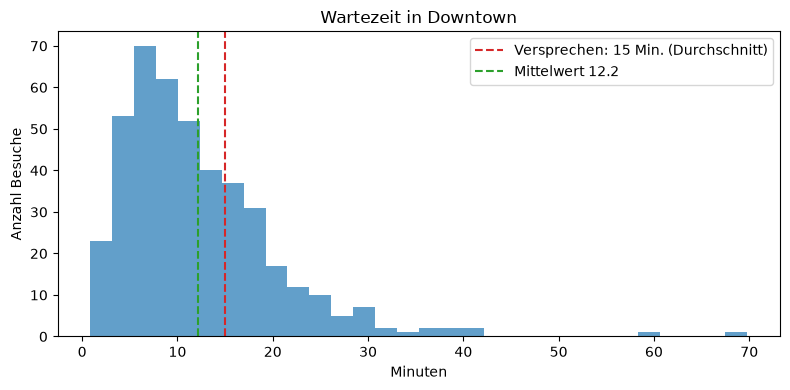

In [15]:
downtown = df[df["clinic_site"] == "Downtown"]["wait_time_min"].dropna()
t_stat, p_two = stats.ttest_1samp(downtown, 15)
p_one = p_two / 2   # einseitig; gilt nur, weil t_stat auf der Seite von H1 liegt (negativ)
print(len(downtown), downtown.mean().round(2), downtown.std(ddof=1).round(2))
print(f"t = {t_stat:.2f}, p (zweiseitig) = {p_two:.2e}, p (einseitig) = {p_one:.2e}, df = {len(downtown) - 1}")

# Gegenprobe 1: dieselbe Rechnung mit der eingebauten einseitigen Variante
print("alternative='less':", stats.ttest_1samp(downtown, 15, alternative="less").pvalue)
# Gegenprobe 2: bereinigte Daten
dt_clean = clean[clean["clinic_site"] == "Downtown"]["wait_time_min"]
print(f"bereinigt: n = {len(dt_clean)}, Mittel {dt_clean.mean():.2f}, p (einseitig) = {stats.ttest_1samp(dt_clean, 15, alternative='less').pvalue:.2e}")

# Zusatz fürs Verständnis: Größe und Streuung
ci_oben = downtown.mean() + stats.t.ppf(0.95, len(downtown) - 1) * stats.sem(downtown)
print(f"95 %-Obergrenze für den Mittelwert: {ci_oben:.2f} Minuten | Anteil Patienten über 15 Min.: {(downtown > 15).mean() * 100:.1f} % | Median {downtown.median():.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(downtown, bins=30, color="tab:blue", alpha=.7)
ax.axvline(15, color="tab:red", ls="--", label="Versprechen: 15 Min. (Durchschnitt)")
ax.axvline(downtown.mean(), color="tab:green", ls="--", label=f"Mittelwert {downtown.mean():.1f}")
ax.set(title="Wartezeit in Downtown", xlabel="Minuten", ylabel="Anzahl Besuche"); ax.legend()
plt.tight_layout(); plt.savefig(ABB / "abb2_downtown.png", dpi=150); plt.show()

*Aussage dieses Diagramms:* Der Durchschnitt liegt klar unter 15 Minuten, aber rund 28 % der einzelnen Patienten warten trotzdem länger als 15 Minuten.

## Antworten Checkpoint 2

**1. Was behaupten die Hypothesen, und welche schützt der Test?**
Die Nullhypothese sagt: Downtown hält das Versprechen **nicht**, die Patienten warten im Schnitt 15 Minuten oder länger. Die Alternative sagt: Sie warten im Schnitt **weniger** als 15 Minuten. Der Test **schützt die Nullhypothese**: Sie gilt so lange, bis die Daten nur noch schwer anders zu erklären sind. Ein nicht signifikantes Ergebnis hieße deshalb nicht „das Versprechen wird gebrochen“, sondern nur „die Daten reichen nicht, um es zu belegen“.

**2. Was bedeutet α = 0,05, und was änderte sich bei α = 0,01?**
Operations nimmt in Kauf, in höchstens 5 % der Fälle zu behaupten „Downtown hält das Versprechen“, obwohl es in Wahrheit nicht stimmt. Die Schwelle wird vor dem Blick auf die Daten festgelegt. Bei α = 0,01 wäre die Hürde strenger: Man sagt nur noch bei sehr starker Evidenz „Versprechen belegt“ und übersieht dafür häufiger echte Verbesserungen. Hier ändert sich nichts am Ergebnis, weil der p-Wert (≈ 1,3 · 10⁻¹²) weit unter beiden Schwellen liegt.

**3. Welche Verteilung, und was bewirkt df = 429?**
Die **t-Verteilung**, nicht die Normalverteilung. Die Streuung der Wartezeiten war vorher unbekannt und wurde aus denselben 430 Besuchen geschätzt. Diese zusätzliche Unsicherheit gibt die t-Verteilung mit etwas breiteren Rändern wieder. Die 429 Freiheitsgrade sind die Zahl der Besuche minus 1 (430 − 1). Sie bestimmen, wie breit die Ränder sind. Bei so vielen Besuchen ist die t-Verteilung fast nicht von der Normalverteilung zu unterscheiden, das Prinzip bleibt aber richtig.

**4. Warum ein Rand, und wann wäre das Halbieren falsch gewesen?**
Die Alternative lautet „kleiner als 15“, und nur das ist für die Frage interessant (Versprechen eingehalten ja oder nein). Die Richtung stand fest, bevor die Daten da waren. Der zweiseitige p-Wert (≈ 2,7 · 10⁻¹²) wäre doppelt so groß und würde auch Abweichungen nach oben als Evidenz zählen, die gar nichts mit der Frage zu tun haben. Die Division durch 2 wäre **stark falsch** gewesen, wenn der Stichprobenmittelwert **über** 15 gelegen hätte (t positiv): Dann wäre der richtige einseitige p-Wert nahe 1 und nicht klein.

**5. Was bedeutet p = 0,0000000000013, und was sagt Operations die Schlussfolgerung?**
*Wenn die wahre mittlere Wartezeit in Downtown tatsächlich 15 Minuten (oder mehr) wäre, dann wäre es extrem unwahrscheinlich (etwa 1 zu einer Billion), in 430 Besuchen einen Durchschnitt zu sehen, der so weit unter 15 liegt wie 12,2 Minuten.* Schlussfolgerung für Operations: **Die Daten dieses Quartals stützen das Versprechen** für den Durchschnitt in Downtown (geschätzt rund 12,2 Minuten, Obergrenze ca. 12,8). Der p-Wert sagt **nicht**, wie groß die Verbesserung ist (das zeigt das Intervall) und **nicht**, dass jeder Patient unter 15 Minuten wartet: Rund 28 % warten länger.

---
# Teil 3 – Checkpoint 3: Einen zweiseitigen Vergleich lesen

Der Standortleiter von Riverside sagt, die Patienten dort warteten nicht länger als in Downtown, und jede sichtbare Differenz sei nur Rauschen aus einer kleineren Stichprobe.

- H₀: Riverside und Downtown haben dieselbe wahre mittlere Wartezeit.
- H₁: Die beiden Standorte haben **unterschiedliche** wahre mittlere Wartezeiten.

Riverside n = 290, Mittel 20.72, SD 8.45
Downtown  n = 430, Mittel 12.18, SD 8.12
Differenz = 8.54 Min. | t = 13.51 | p (zweiseitig) = 1.55e-36 | Welch-df = 604
95 %-Intervall der Differenz: 7.30 bis 9.78 Minuten | Cohens d = 1.03

Ohne Welch (gleiche Varianz angenommen): t = 13.61, p = 1.03e-37  -> hier fast identisch
bereinigt (n Riverside = 286): Differenz 8.58, Intervall 7.33 bis 9.82, d = 1.04, p = 1.0e-36


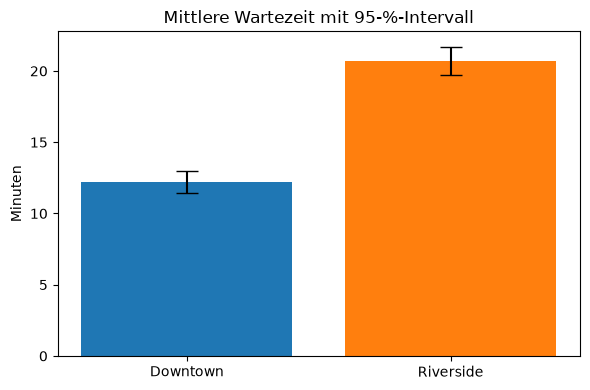

In [16]:
riverside = df[df["clinic_site"] == "Riverside"]["wait_time_min"].dropna()
downtown = df[df["clinic_site"] == "Downtown"]["wait_time_min"].dropna()


def welch(a, b, alpha=0.05):
    """Welch-Test mit 95-%-Intervall für die Differenz (a - b) und Cohens d."""
    t, p = stats.ttest_ind(a, b, equal_var=False)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se, diff = np.sqrt(va + vb), a.mean() - b.mean()
    dfw = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    k = stats.t.ppf(1 - alpha / 2, dfw)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return dict(t=t, p=p, diff=diff, ci=(diff - k * se, diff + k * se), d=diff / sp, df=dfw)


res = welch(riverside, downtown)
print(f"Riverside n = {len(riverside)}, Mittel {riverside.mean():.2f}, SD {riverside.std(ddof=1):.2f}")
print(f"Downtown  n = {len(downtown)}, Mittel {downtown.mean():.2f}, SD {downtown.std(ddof=1):.2f}")
print(f"Differenz = {res['diff']:.2f} Min. | t = {res['t']:.2f} | p (zweiseitig) = {res['p']:.2e} | Welch-df = {res['df']:.0f}")
print(f"95 %-Intervall der Differenz: {res['ci'][0]:.2f} bis {res['ci'][1]:.2f} Minuten | Cohens d = {res['d']:.2f}")

# Gegenprobe 1: klassischer Test mit gleicher Varianz
t2, p2_ = stats.ttest_ind(riverside, downtown, equal_var=True)
print(f"\nOhne Welch (gleiche Varianz angenommen): t = {t2:.2f}, p = {p2_:.2e}  -> hier fast identisch")
# Gegenprobe 2: bereinigte Daten
rc = clean[clean["clinic_site"] == "Riverside"]["wait_time_min"]
dc = clean[clean["clinic_site"] == "Downtown"]["wait_time_min"]
rc_res = welch(rc, dc)
print(f"bereinigt (n Riverside = {len(rc)}): Differenz {rc_res['diff']:.2f}, Intervall {rc_res['ci'][0]:.2f} bis {rc_res['ci'][1]:.2f}, d = {rc_res['d']:.2f}, p = {rc_res['p']:.1e}")

fig, ax = plt.subplots(figsize=(6, 4))
mw = [downtown.mean(), riverside.mean()]
fehler = [stats.sem(downtown) * stats.t.ppf(.975, len(downtown) - 1), stats.sem(riverside) * stats.t.ppf(.975, len(riverside) - 1)]
ax.bar(["Downtown", "Riverside"], mw, yerr=fehler, capsize=8, color=["tab:blue", "tab:orange"])
ax.set(title="Mittlere Wartezeit mit 95-%-Intervall", ylabel="Minuten")
plt.tight_layout(); plt.savefig(ABB / "abb3_standorte.png", dpi=150); plt.show()

*Aussage dieses Diagramms:* Riverside wartet im Schnitt rund 8,5 Minuten länger als Downtown, und die Intervalle der beiden Standorte überlappen sich nicht.

## Antworten Checkpoint 3

**1. Hypothesen und warum zweiseitig?**
Die Nullhypothese sagt: Beide Standorte haben dieselbe wahre mittlere Wartezeit. Die Alternative: Sie unterscheiden sich. Die Zahl der Seiten hängt von der **Frage** ab, nicht von einer Vermutung. Regional Operations würde bei **jedem** Ergebnis handeln: Wäre Riverside *schneller*, würde die Personalentscheidung ebenfalls anders ausfallen (andere Richtung der Versetzung). Beide Richtungen sind also bedeutsam. In Checkpoint 2 dagegen zählte nur eine Richtung (Versprechen eingehalten, ja oder nein).

**2. Welcher Test, und was ändert `equal_var=False`?**
Ein **Zwei-Stichproben-t-Test nach Welch** (t-Verteilung). Der ältere Test nimmt an, dass beide Standorte gleich stark streuen, und rechnet mit einer gemeinsamen Streuung. Welch lässt jede Gruppe ihre **eigene** Streuung behalten und passt die Freiheitsgrade an (hier ≈ 604). Das ist der sichere Standard, weil die Gruppen **ungleich groß** sind (290 gegen 430): Streuen sie dann unterschiedlich, kann der klassische Test zu optimistische oder zu vorsichtige Ergebnisse liefern. Sind die Streuungen gleich (wie hier: 8,45 und 8,12), kostet Welch praktisch nichts, das Ergebnis ist fast identisch.

**3. Typ-I- und Typ-II-Fehler bei dieser Entscheidung**
Ein **Typ-I-Fehler**: Wir schließen „Riverside wartet länger“, obwohl die Standorte in Wahrheit gleich sind. Folge: Zwei Mitarbeitende werden **unnötig versetzt**, an der Stelle, von der sie kommen, fehlen sie, Kosten und Unruhe entstehen ohne Nutzen. Ein **Typ-II-Fehler**: Wir schließen „kein Unterschied“, obwohl Riverside wirklich länger wartet. Folge: Die Patienten dort warten weiter länger, und die Hilfe kommt nicht. Das Signifikanzniveau (α) setzt eine Obergrenze für den **Typ-I-Fehler**. Über den Typ-II-Fehler enthält die Ausgabe **keine Information**; er hängt von der Stichprobengröße und der Größe des Unterschieds ab.

**4. Was belegt p ≈ 10⁻³⁶, und was zeigst du Operations?**
Der p-Wert belegt, dass ein Unterschied dieser Größe bei **gleicher** wahrer Wartezeit praktisch nicht durch Zufall entstehen würde. Das widerlegt die Behauptung „nur Rauschen“. Er sagt **nicht**, wie groß der Unterschied ist, und nicht, ob er für die Entscheidung relevant ist. Ich würde der Operations-Leitung das **Konfidenzintervall** zeigen: *Riverside wartet durchschnittlich zwischen etwa 7,3 und 9,8 Minuten länger als Downtown.* Das ist die Zahl, mit der man Personal plant. Cohens d (≈ 1,03, groß) ordnet die Größe im Verhältnis zur Streuung der Patienten ein und ist ein guter Zusatz, der p-Wert selbst gehört nicht auf die Folie.

---
# Teil 4 – Checkpoint 4: Sollte dieser Test überhaupt durchgeführt werden?

*Design-Review ohne Datensatz.* Geprüft wird der Plan des Operations-Teams für eine SMS-Erinnerung 24 Stunden vor dem Termin, um No-Shows zu senken.

## Die sechs Annahmen, einzeln geprüft

| # | Annahme | Erfüllt? | Zitat aus dem Plan, das sie verletzt |
|---|---|---|---|
| 1 | **Zufällige Zuteilung** | ❌ verletzt | „Riverside wurde ausgewählt, weil sich der Site Manager freiwillig gemeldet hat und weil die No-Show-Rate dort am höchsten ist“. Freiwilligkeit und hoher Bedarf sind Auswahl, nicht Zufall. |
| 2 | **Unabhängigkeit der Einheiten** | ❌ verletzt | „Riverside erhält im gesamten März die neue SMS-Erinnerung. Downtown behält den aktuellen Prozess“. Die Zuteilung gilt je Standort, nicht je Besuch. Es gibt nur **eine Einheit pro Arm**: Besuche am selben Standort teilen Personal, Abläufe und Patientenstamm. |
| 3 | **Keine Interferenz zwischen den Armen** | ❌ verletzt | „Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden.“ Die Kontrolle erlebt nicht mehr den Status quo. Zusätzlich: „… begann Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen“. Das Treatment ist nicht mehr nur eine SMS. |
| 4 | **Gleichzeitigkeit** | ❌ verletzt | „Vergleiche die No-Show-Rate von Riverside im März mit der Rate von Downtown im Februar“. Zwei verschiedene Monate, Saison und Wetter treffen die Arme unterschiedlich. |
| 5 | **Vorab deklarierte primäre Kennzahl, gleich gemessen** | ❌ verletzt | „Wir sehen uns No-Shows an und außerdem Wartezeiten, Zufriedenheit und Umsatz pro Besuch und berichten, was sich davon bewegt.“ Keine primäre Kennzahl, und „weil die Februar-Zahlen … bereits bereinigt und geladen wurden“: Februar (Kontrolle) und März (Treatment) werden unterschiedlich aufbereitet. |
| 6 | **Ausreichende Power** | ❌ verletzt | „Riverside hat ungefähr 290 Besuche pro Quartal, Downtown ungefähr 430 … erwartet, dass die Erinnerung No-Shows um etwa 2 Prozentpunkte senkt.“ März allein sind nur etwa ein Drittel davon. Siehe Rechenbeispiel unten. |

In [17]:
# Rechenbeispiel zu Annahme 6 (Illustration): Grundrate aus der Quartalsauswertung, Effekt laut Plan: 2 Prozentpunkte
def n_pro_arm(p1, p2, alpha=0.05, power=0.8):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    pb = (p1 + p2) / 2
    return (za * np.sqrt(2 * pb * (1 - pb)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p1 - p2) ** 2


def power_bei(p1, p2, n1, n2, alpha=0.05):
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return stats.norm.cdf(abs(p1 - p2) / se - stats.norm.ppf(1 - alpha / 2))


grundrate = clean["no_show"].mean()
print(f"Grundrate No-Show (alle Kliniken): {grundrate * 100:.1f} %")
print(f"Besuche je Arm für 2 Prozentpunkte weniger (Power 80 %): ca. {n_pro_arm(grundrate, grundrate - 0.02):,.0f}")
print(f"Power mit den geplanten Mengen (März: ~1/3 von 290 und 430): {power_bei(grundrate, grundrate - 0.02, 97, 143) * 100:.0f} %")

# Randnotiz: Stimmt die Behauptung im Plan, Riverside habe die höchste No-Show-Rate?
print("\nNo-Show-Rate je Klinik (Daten dieses Quartals):")
print((clean.groupby("clinic_site")["no_show"].mean() * 100).round(1).sort_values(ascending=False).to_string())

Grundrate No-Show (alle Kliniken): 10.8 %
Besuche je Arm für 2 Prozentpunkte weniger (Power 80 %): ca. 3,452
Power mit den geplanten Mengen (März: ~1/3 von 290 und 430): 7 %

No-Show-Rate je Klinik (Daten dieses Quartals):
clinic_site
Eastview     12.7
Downtown     11.6
Riverside     9.4
Northgate     9.1


**Rechenbeispiel:** Um einen Rückgang von 2 Prozentpunkten (bei rund 11 % Grundrate) mit 80 % Power zu erkennen, brauchte man **rund 3.500 Besuche je Arm**. Der Plan hat für März rund 100 (Riverside) und 140 (Downtown): die Chance, einen echten Effekt dieser Größe überhaupt zu finden, liegt bei rund 7 %.

*Randnotiz (nicht Teil der Review, aber auffällig):* In den Daten dieses Quartals hat Riverside **nicht** die höchste No-Show-Rate (rund 9 %, nach Eastview und Downtown). Die Begründung „höchste No-Show-Rate, also größtes Verbesserungspotenzial“ sollte der Plan belegen, sie deckt sich nicht mit `solace_visits.csv`.

## Urteil in einem Satz

> **Der Plan sollte so nicht durchgeführt werden, weil Riverside freiwillig und wegen hohen Bedarfs ausgewählt und mit Downtown in einem anderen Monat verglichen wird: Jeder Unterschied wäre nicht von Standort, Jahreszeit und Auswahl zu trennen, und das lässt sich durch Umschreiben nicht beheben.**

**Die Verletzung, die das Urteil entscheidet:** Annahme 1 (zufällige Zuteilung) in Verbindung mit der Struktur „ein Standort gegen einen Standort“. Sie ist in den Vergleich **eingebaut**: Selbst wenn man Kennzahl, Monate und Messung korrigiert, bleibt ein Unterschied zwischen *Riverside* und *Downtown*, den man nicht von der SMS trennen kann. **Reparierbar durch Umschreiben** wären dagegen die Annahmen 4 (gleicher Zeitraum), 5 (eine vorab festgelegte Kennzahl, gleich gemessen) und 6 (ausreichend lange laufen lassen oder größeren Effekt zugrunde legen). Annahme 3 (Interferenz) ist durch klare Regeln für das Front-Desk-Team zu begrenzen.

**Wo hätte ein Ergebnis signifikant werden können, ohne etwas zu bedeuten?** Beim Vergleich „Riverside im März gegen Downtown im Februar“. Ein Unterschied hätte jeden Grund haben können (Standort, Monat, Freiwilligkeit des Managers, andere Aufbereitung der Zahlen), und bei vier berichteten Kennzahlen („berichten, was sich bewegt“) wäre irgendeine mit Glück ohnehin „signifikant“ gewesen.

## Redesign: eine gültige Version

1. **Randomisierung auf Besuchsebene über alle vier Standorte:** Jeder Termin wird per Zufall der SMS-Gruppe oder der Gruppe ohne Erinnerung zugeteilt, im selben Zeitraum.
2. **Eine vorab festgelegte primäre Kennzahl:** No-Show-Rate pro Termin, in beiden Gruppen identisch gemessen. Wartezeit, Zufriedenheit und Umsatz höchstens als ausdrücklich zweitrangig.
3. **Stichprobe vorher berechnen:** für 2 Prozentpunkte rund 3.500 Termine je Gruppe, bei den aktuellen Mengen (~1.200 Besuche pro Quartal) also deutlich länger als ein Quartal, oder einen größeren Mindesteffekt festlegen, der geschäftlich zählt.
4. **Regeln für das Front-Desk-Team:** keine zusätzlichen Erinnerungen an beide Gruppen, Abweichungen werden protokolliert.
5. **Feste Laufzeit und Auswertung nach Plan**, nicht stoppen, wenn es gut aussieht.

**Falls das nicht möglich ist** (z. B. weil sich Termine technisch nicht randomisieren lassen): Standorte zufällig und zeitlich versetzt umstellen oder, wenn auch das nicht geht, den Vergleich **offen als Beobachtungsstudie** durchführen (Vorher-Nachher mit Vergleichsstandorten) und das Ergebnis nur als Hinweis, nicht als Nachweis einer Wirkung berichten.

---
# Teil 5 – Grenzen: Was diese Evidenz nicht belegen kann

- Sie belegt **nicht**, dass jeder Patient in Downtown unter 15 Minuten wartet (rund 28 % warten länger).
- Sie belegt **nicht, warum** Riverside länger wartet. Der Test zeigt einen Unterschied, aber keine Ursache.
- Sie sagt **nichts darüber**, ob eine SMS-Erinnerung No-Shows senkt. Dafür gibt es in diesem Datensatz keine Daten, und der vorgeschlagene Plan würde es auch nicht klären.
- Die Zufriedenheitswerte fehlen vor allem bei Urgent. Aussagen über Zufriedenheit gelten nur für die, die geantwortet haben.